# KI-TWPA serpentine (NY CREATES geometry via twpa-sim), rebuilt in the Quantcore PDK

**What it is.** A kinetic-inductance travelling-wave parametric amplifier: a long artificial transmission line of a
thin superconducting film whose inductance depends on the current, L(I) = L0 (1 + I²/I*²). A DC bias plus a pump
give three-wave mixing (pump → signal + idler) along the line; periodic *loaded* cells (shorter capacitive fingers)
open a stop band that keeps the pump's third harmonic from propagating and sets the phase matching (Eom et al.,
Nat. Phys. 8, 623 (2012); Malnou et al., PRX Quantum 2, 010302 (2021)).

**Source.** twpa-sim (S. Mandal, MIT) `src/twpa/layout/kit.py` + `KITLayout`, a parameterised port of the
NY CREATES research layout (`kit_nycreates_research.json`): NbN 60 nm, 20 pH/□; a 0.58 µm spine with 0.5 µm gaps;
0.5 µm fingers in 0.25 µm slots, 75.5 µm long (27.5 µm on the loaded cells); supercells of 24 + 6 + 24 cells at a
1.5 µm pitch; 16 rows × 55 supercells joined by U-turns of radius 154 µm (3 supercells each) — 49 950 cells, the
electrical `v2-standard` line (925 supercells; L 53.8 pH, C 22.3 / 8.4 fF per cell). Read-only clone
`build/external/twpa-sim` (rev 05abc83), never run.

| | source | Quantcore rebuild (why) |
|---|---|---|
| geometry | 16 × 55 serpentine, radial turn fingers, turn spine widened to match sheet squares | the same (`KiTwpaSerpentine`: twpa-sim's primitives re-drawn as a negative mask) |
| film | **NbN 60 nm, 20 pH/□** | **PDK Nb 200 nm, 0.116 pH/□**: ≈ 170× less kinetic inductance |
| line impedance | ≈ 50 Ω (L dominated by kinetic inductance) | **≈ 6 Ω on Nb** and weakly nonlinear (kinetic share ≈ 30 %): flagged; the NbN case is shown in the analysis only, via a `KineticInductance(sheet_inductance_pH_sq=20)` override (no PDK change) |
| grounds | two separate ground combs (package grounding) | one chip ground plane |
| launches | 103 µm bump-landing bays | tapers from the spine to the 10/6 µm chip CPW, Quantcore `BondPad`s 100 µm from the edge |
| chip | 5 × 5 mm | 7.5 × 7.5 mm PDK die; both launches on the west side (even row count, as the source), so the content sits off-centre in x |

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far — the 7.5 mm die, the two bond pads on the west edge, the feed lines (none of
their own: signal, pump and bias share the two feeds, which end on the serpentine's launches), the kinetic-inductance
serpentine, the two feeds, and then the whole chip (the sim group, the save). Then the same steps as the Flow strip of
the Quantcore KLayout plugin: **Check** (DRC, netlist) → **LOM** (the amplifier's circuit models, their plots, one
change by hand) → **Simulate** (export to HFSS and the line's Q3D C-matrix; no eigenmode or full-wave run of an 18 mm
line, said why) → **Results** (the Q3D capacitance read as C per cell, against the LOM ladder, a feedback step and the
iteration to a 50 Ω line on the source film) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in four cells, with its outputs) is kept as `ki_twpa_serpentine.v1.ipynb`; both save the same
`ki_twpa_serpentine.json`.

## Setup

The imports, the output folder and the switches. `_amplifiers` holds the amplifier notebooks' helpers (the PDK
facts, value tables, plots, the linear S-parameters of a LOM netlist, and the readers that put kept FEM results in
amplifier terms); `_common` the helpers all design notebooks share (tables, snapshots, the PDK placement, the FEM and
feedback steps). The physics is `quantcore_circuits.analysis.amplifiers`, the cells
`quantcore_circuits.layouts.others.amplifiers`.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files.

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
import os, sys, time
from dataclasses import replace
from pathlib import Path
import numpy as np
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "amplifiers"))
from _common import *
from _amplifiers import pdk_facts_md, plot, show_md, table_md
from _amplifiers import cmatrix_to_ground   # v2: kept FEM results in amplifier terms (Results)
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import KineticInductance, get_pdk
from quantcore_circuits.analysis import amplifiers as amp
from quantcore_circuits.layouts.others.amplifiers import KiTwpaSerpentine

LIVE = os.environ.get("QCC_LIVE", "1") == "1"
FULL_SIZE = False        # True: draw the 16-row reference (49 950 cells; the build takes minutes, see Design 2)
OUT = Path("examples/designs/amplifiers")
PDK = get_pdk()
NBN = replace(PDK, kinetic=KineticInductance(sheet_inductance_pH_sq=20.0))   # the source film, analysis only

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the film's kinetic inductance, the cheese and the 3/0
keep-outs. For this chip the film matters most: the PDK's 200 nm Nb has a sheet kinetic inductance of only ≈ 0.12 pH/□
(the table), against the source's 20 pH/□ NbN, so the drawn line is mostly geometric inductance. The source film is
used in the analysis only, through a `KineticInductance` override (`NBN`, Setup); the PDK is not changed.

In [4]:
show_md(pdk_facts_md(PDK))

| PDK | value |
|---|---|
| substrate | sapphire 650 µm, εr 10.25 |
| film | Nb 200 nm, λ_L 90 nm → L_s 0.116 pH/□ (kinetic, in every CPW / wire formula) |
| junction rule | Nb/AlOx/Nb trilayer, Δ 1.4 meV, J_c 0.163 µA/µm², R_n window 40–50 kΩ, fingers 0.1–2 µm |
| frame | die 7.5 × 7.5 mm standard, margin 100 µm, marker areas 500 µm, brand QCT |
| pad rule | outer etch 100 µm (one dicing-marker width) from the die edge (`edge="auto"`) |
| cheese | PDK band 3 rows of 5 µm squares, 20 µm gap, around the 3/0 keep-outs (unless the original has its own) |
| 3/0 keep-out | routes + 10 µm, components + 24 µm |

# Design: the layout, one segment at a time

An amplifier chip is laid out the way a designer would do it by hand: the die, the bond pads, the feed (and pump)
line, the nonlinear element, the routing, and then the whole chip. Each segment is one cell with one picture of the
chip so far (and, live, KLayout redraws after every cell). A route always joins two ports, so a line is drawn once
both of its ends exist. The line under each picture counts what is on the chip; it says 0 qubits: an amplifier has
none, its junctions sit inside the amplifier cell (counted among the other components).

| segment | what is placed here |
|---|---|
| 1 | the 7.5 × 7.5 mm die with the QCT frame |
| 2 | the input and output `BondPad`s on the west edge, at the heights of the first and last rows |
| 3 | the feed lines: none of their own (signal, pump and DC bias share the two feeds, which end on the serpentine's launches: Design 5) |
| 4 | the nonlinear element: the `KiTwpaSerpentine` (rows of supercells, U-turns, the launch tapers) and its ladder values |
| 5 | the routing: the two short 50 Ω feeds, pad → launch |
| 6 | the whole chip: the sim group, the save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip: a standard 7.5 × 7.5 mm Quantcore die (the source's is 5 × 5 mm), on
which the PDK draws the **QCT frame** — the L dicing markers, the corner marker areas, the chip boundary and the
device ID (`name_chip` "KITWPA") on a free edge.

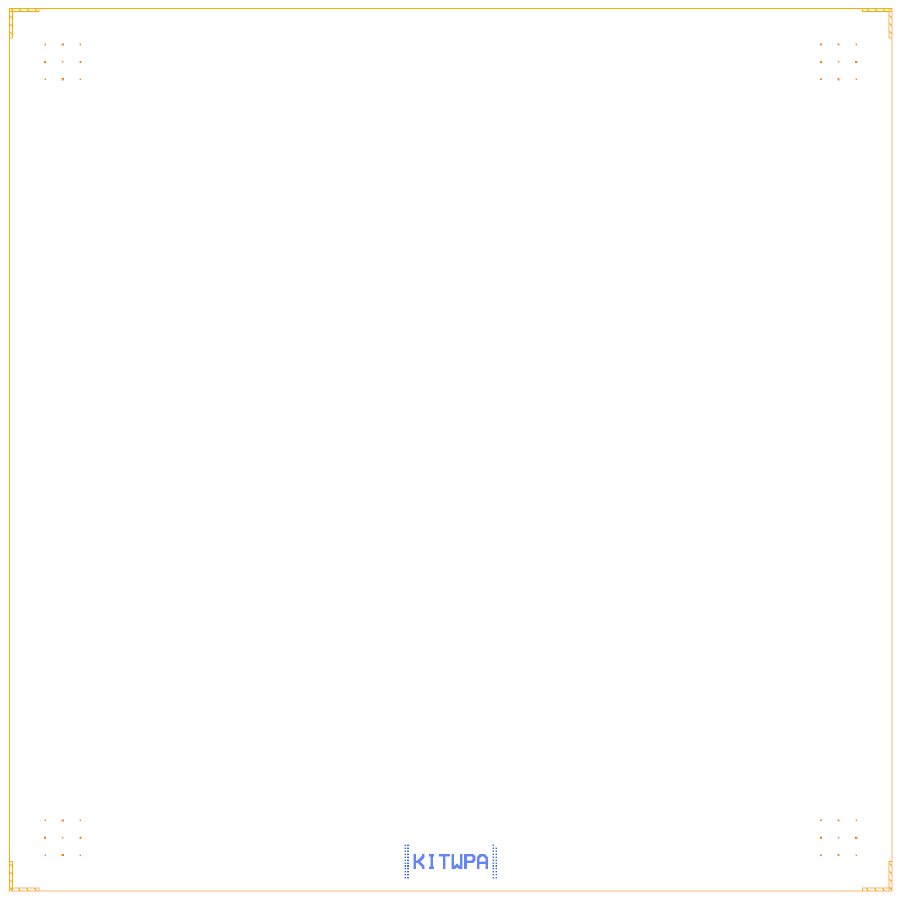

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/amplifiers/ki_twpa_serpentine_s1_die.png')

In [5]:
W = H = 7500
d = Designer("ki_twpa_serpentine", box=(0, 0, W, H), chip={"name_chip": "KITWPA"}, live=LIVE)
layout_step(d, OUT / "ki_twpa_serpentine_s1_die.png", size=(900, 900), width=400)

## Design 2 · Bond pads (the 100 µm rule)
Input and output `BondPad`s on the west edge at the heights of the first and last rows. `edge="auto"` slides each pad
perpendicular to its die edge until its outer etch is the PDK `pad_edge` (100 µm) from it. An even number of rows ends
the line on the side it starts, so both pads are on the west edge; their heights come from `N_ROWS` and the 154 µm
turn radius. `KIT` and `REF` (the drawn and the source line's parameters) and the serpentine's centre are defined here
too.

**Size.** The saved design draws 4 rows of the full 55-supercell length (12 366 cells with the U-turns; the v1 run's
ladder: 229 supercells); `FULL_SIZE = True` draws the 16-row reference (49 950 cells). The full line merges into two
etch polygons of ≈ 0.8 M vertices and the build's 3/0 step grows the whole etch by 5 µm (≈ 2 min); the analysis below
always uses the 49 950-cell line.

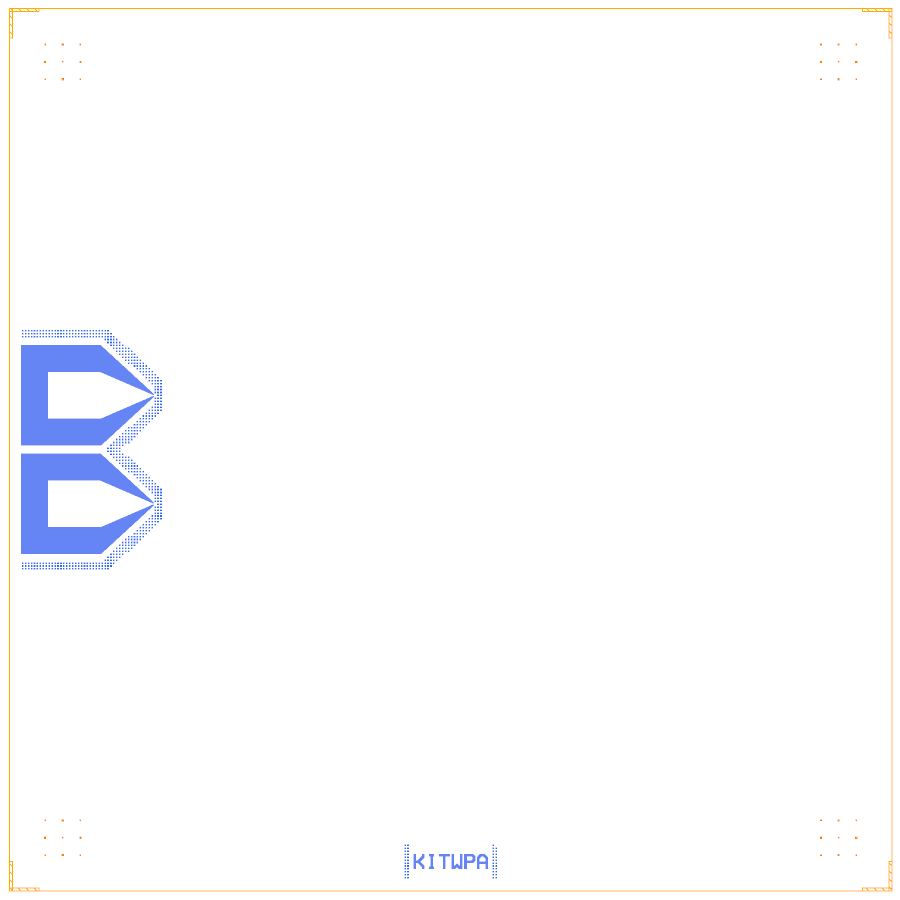

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `P_IN`, `P_OUT`.

WindowsPath('examples/designs/amplifiers/ki_twpa_serpentine_s2_pads.png')

In [6]:
N_ROWS = 16 if FULL_SIZE else 4
KIT = dict(rows=N_ROWS, periods_per_row=55)
REF = dict(rows=16, periods_per_row=55)   # the source line
XK, YK = 4000, 3750                                # serpentine centre (rows along x)
with d.batch():
    d.add("P_IN", "BondPad", at=(400, YK + (N_ROWS - 1) * 154), rot=-90, edge="auto")
    d.add("P_OUT", "BondPad", at=(400, YK - (N_ROWS - 1) * 154), rot=-90, edge="auto")
layout_step(d, OUT / "ki_twpa_serpentine_s2_pads.png", size=(900, 900), width=400)

## Design 3 · The feed lines come with the serpentine

A KI-TWPA is a two-port line: the signal, the pump and the DC bias that makes the mixing three-wave all travel the
same line, so there is no separate pump or bias line to place. The two feeds end on the serpentine's own launches
(`KIT.a`, `KIT.b`), so they are drawn in Design 5, once the serpentine is there. Nothing to place here.

## Design 4 · The nonlinear element: the kinetic-inductance serpentine
`KIT` (`KiTwpaSerpentine`): the rows are arrays of one supercell etch (spine gaps + finger slots), the U-turns
twpa-sim's constant-width radial fingers with the smooth-step widened spine (the sheet-square match is solved per
build, `brentq`); the launches taper the 0.58 µm spine to the 10/6 µm CPW over 88 µm and run 155 µm to the ports.

The table puts the drawn line's per-cell values (PDK Nb) next to the same drawing on the source's NbN film (the
override, analysis only) and twpa-sim's calibrated cell: on Nb the kinetic share α_k is small and the line far below
50 Ω, which is what the rest of the notebook works with. The picture is the chip so far (the zooms on a U-turn, the
cells and a launch are in Fab 2).

| per cell | PDK Nb (drawn) | NbN 20 pH/□ (override) | twpa-sim v2 (calibrated) |
|---|---|---|---|
| sheet L_s (pH/□) | 0.1158 | 20 | 20 |
| L geometric (pH) | 0.7063 | 0.7063 | – |
| L kinetic (pH) | 0.2994 | 51.72 | – |
| L total (pH) | 1.006 | 52.43 | 53.79 |
| kinetic share α_k | 0.2977 | 0.9865 | 1 |
| C unloaded / loaded (fF) | 23.6 / 8.6 | 23.6 / 8.6 | 22.3 / 8.4 |
| Z = √(L/C) (Ω) | 6.531 | 47.15 | 49.09 |
| cells / supercells (reference) | 49950 / 925 | same | 49 950 / 925 |

Drawn on this die: 12366 cells (229 supercells, 18.5 mm of line).

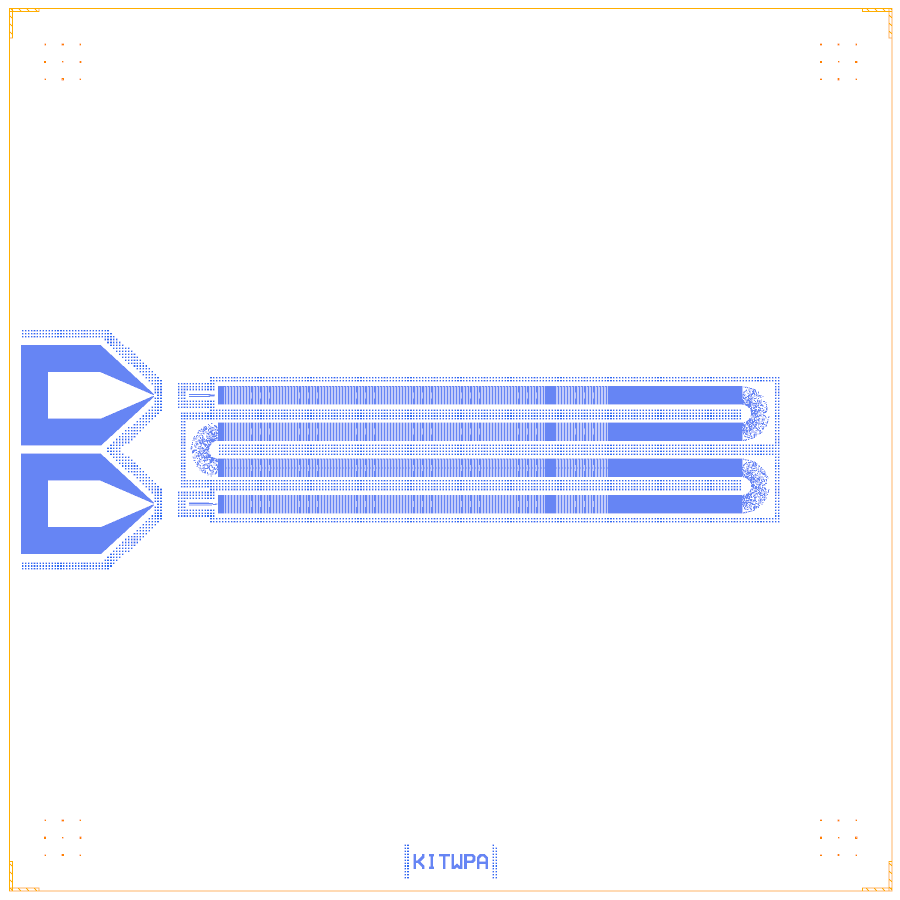

**On the chip so far:** 2 pads · 0 qubits · 1 other components · 0 routes · 0 declared couplings. **This step added** 1 component(s) `KIT`.

WindowsPath('examples/designs/amplifiers/ki_twpa_serpentine_s4_serpentine.png')

In [7]:
t0 = time.time()
with d.batch():
    d.add("KIT", "KiTwpaSerpentine", at=(XK, YK), **KIT)
LAD_NB = KiTwpaSerpentine.qcc_ladder(REF, PDK)
LAD_NBN = KiTwpaSerpentine.qcc_ladder(REF, NBN)
DRAWN = KiTwpaSerpentine.qcc_ladder(KIT, PDK)
SRC = {"L_cell_pH": 20 * (1.5 / 0.58) * 1.04, "C_cell_fF": 22.32, "C_loaded_fF": 8.38}   # twpa-sim v2 preset
show_md(table_md(["per cell", "PDK Nb (drawn)", "NbN 20 pH/□ (override)", "twpa-sim v2 (calibrated)"], [
    ["sheet L_s (pH/□)", LAD_NB["sheet_pH_sq"], LAD_NBN["sheet_pH_sq"], 20],
    ["L geometric (pH)", LAD_NB["L_geo_pH"], LAD_NBN["L_geo_pH"], None],
    ["L kinetic (pH)", LAD_NB["L_k_pH"], LAD_NBN["L_k_pH"], None],
    ["L total (pH)", LAD_NB["L_cell_pH"], LAD_NBN["L_cell_pH"], SRC["L_cell_pH"]],
    ["kinetic share α_k", LAD_NB["alpha_k"], LAD_NBN["alpha_k"], 1.0],
    ["C unloaded / loaded (fF)", f"{LAD_NB['C_cell_fF']:.1f} / {LAD_NB['C_loaded_fF']:.1f}",
     f"{LAD_NBN['C_cell_fF']:.1f} / {LAD_NBN['C_loaded_fF']:.1f}", "22.3 / 8.4"],
    ["Z = √(L/C) (Ω)", LAD_NB["Z_cell_ohm"], LAD_NBN["Z_cell_ohm"],
     np.sqrt(SRC["L_cell_pH"] * 1e-12 / (SRC["C_cell_fF"] * 1e-15))],
    ["cells / supercells (reference)", f"{LAD_NB['cells']} / {LAD_NB['supercells']}", "same", "49 950 / 925"]])
    + "\n\n" + f"Drawn on this die: {DRAWN['cells']} cells ({DRAWN['supercells']} supercells, {DRAWN['length_um'] / 1e3:.1f} mm of line).")
layout_step(d, OUT / "ki_twpa_serpentine_s4_serpentine.png", size=(900, 900), width=400)

## Design 5 · Routing: the two feeds
Short 50 Ω feeds from the pads to the two launches. `L_IN` runs `P_IN.a` → `KIT.a`, `L_OUT` `P_OUT.a` → `KIT.b`, in
the PDK's 10/6 µm CPW (the launches taper the 0.58 µm spine to it).

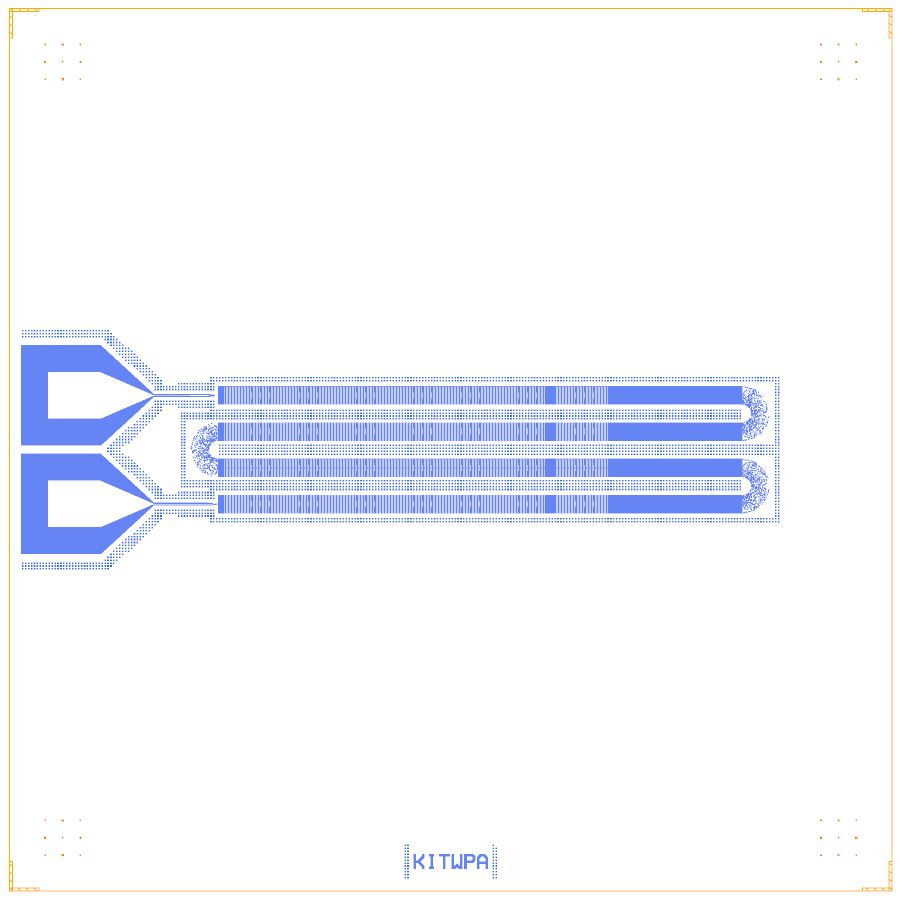

**On the chip so far:** 2 pads · 0 qubits · 1 other components · 2 routes · 0 declared couplings. **This step added** 2 route(s) `L_IN`, `L_OUT`.

WindowsPath('examples/designs/amplifiers/ki_twpa_serpentine_s5_feeds.png')

In [8]:
with d.batch():
    d.route("L_IN", "P_IN.a", "KIT.a")
    d.route("L_OUT", "P_OUT.a", "KIT.b")
layout_step(d, OUT / "ki_twpa_serpentine_s5_feeds.png", size=(900, 900), width=400)

## Design 6 · The whole chip: the sim group, the save

**Sim group.** `launch` boxes the whole serpentine (`KIT`, 40 µm margin) for a Q3D C-matrix; the feeds are cut at the
box edge. The design sets no targets (Results 4 puts one on a copy).

**No centring.** Both launches are on the west side (an even number of rows), so the content sits off-centre in x by
design (Check 1's `pdk_report` measures by how much).

**Save.** `save_design` writes `ki_twpa_serpentine.json` and compares it with the file it replaces (the previous
run's, e.g. the `.v1` notebook's): it should say *same design*. The time printed is the layout's since Design 4 (with
the segment pictures). The picture is the whole chip.

**Same design as before:** `examples/designs/amplifiers/ki_twpa_serpentine.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer ki_twpa_serpentine: 3 instances, 2 routes, live=False> → examples\designs\amplifiers\ki_twpa_serpentine.json (layout built in 10.2 s)


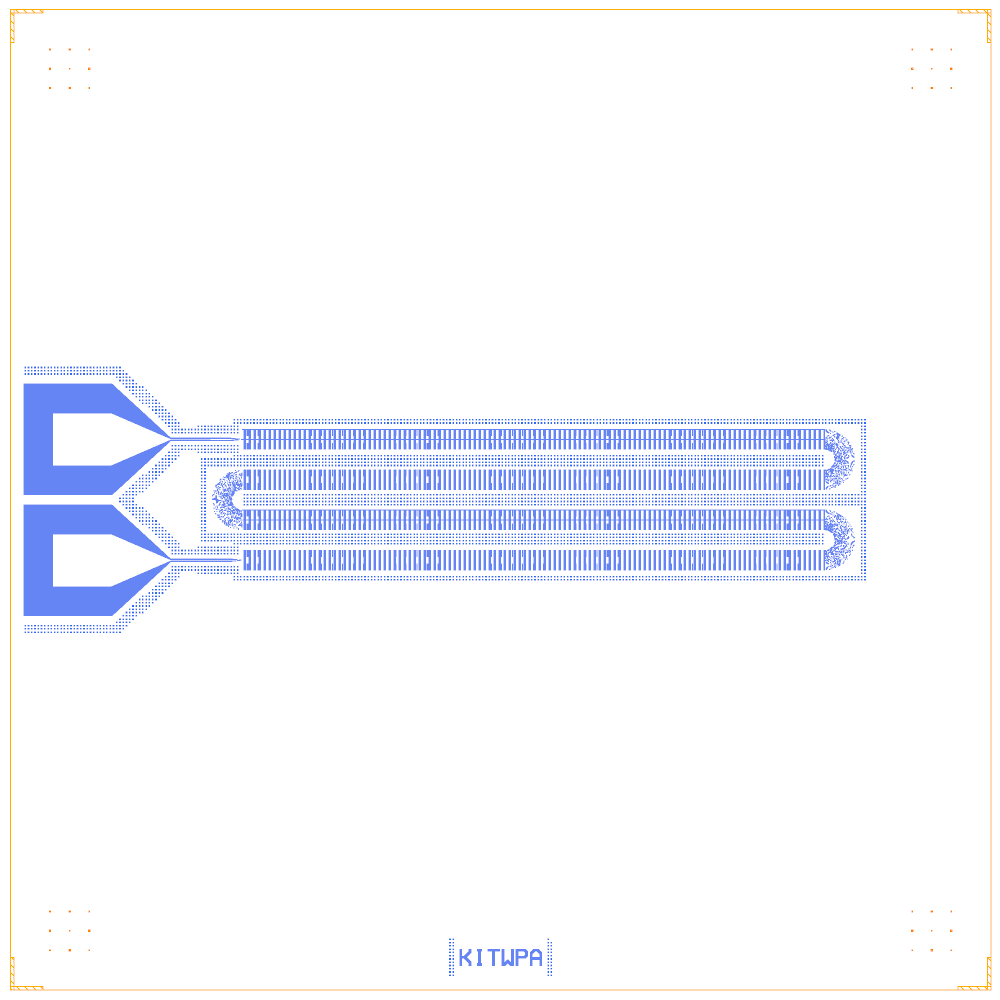

**On the chip so far:** 2 pads · 0 qubits · 1 other components · 2 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/amplifiers/ki_twpa_serpentine_s6_chip.png')

In [9]:
d.sim_group("launch", ["KIT"], margin_um=40, analyses=["q3d_cmatrix"])
if not LIVE:
    d.show()
DESIGN, same = save_design(d, OUT / "ki_twpa_serpentine.json")
display(Markdown(same))
print(d, "→", DESIGN, f"(layout built in {time.time() - t0:.1f} s)")
layout_step(d, OUT / "ki_twpa_serpentine_s6_chip.png", size=(1000, 1000), width=480)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC
No junctions; the content is off-centre in x (both launches on the west side: an even number of rows).

Expected here (from the v1 run): **DRC clean**, no PDK design warnings (no junctions); content centre − die centre
(−471, +0) µm.

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip box
and the frame: **errors** would block fab, **warnings** are layout hints, **PDK design warnings** (`pad_edge`,
`pdk_rn`, …) flag a PDK margin and are never fixed by retuning. `pdk_report(d)` sums up the PDK side.

In [ ]:
print(d.drc())
show_md(pdk_report(d))

## Check 2 · Netlist
`KiTwpaSerpentine`'s model is one conductor between its ports (both pads: a wire, two 50 Ω ports); the ladder that
describes the line — L and C per cell, the loaded cells — comes from `KiTwpaSerpentine.qcc_ladder`, with the
film's L_s from the PDK (`pdk.kinetic`) or an override.

In [ ]:
lb = d.lom()
show_netlist(lb)

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The circuit models

The netlist's wire says nothing about the line; the models are the ladder of `KiTwpaSerpentine.qcc_ladder` (Design 4)
in `analysis.amplifiers`: (a) the supercell's linear response, (b) the three-wave-mixing gain. Their plots are in LOM
2.

**(a) Linear response** of the supercell (24 + 6 + 24 cells, `analysis.amplifiers.ki_supercell`: two fingers per
cell with their stub inductance, L_s × squares / 3): Bloch phase per cell and attenuation, for the PDK Nb drawing,
the same drawing on NbN, and twpa-sim's calibrated v2 cell.

In [ ]:
f = np.linspace(0.05e9, 12e9, 4000)
def unit(lad=None, src=False):
    if src:
        lu, cu, cl = SRC["L_cell_pH"] * 1e-12, SRC["C_cell_fF"] * 1e-15, SRC["C_loaded_fF"] * 1e-15
        su, sl = 20e-12 * (75.5 / 0.5) / 3, 20e-12 * (27.5 / 0.5) / 3
    else:
        lu, cu, cl = lad["L_cell_pH"] * 1e-12, lad["C_cell_fF"] * 1e-15, lad["C_loaded_fF"] * 1e-15
        su, sl = lad["sheet_pH_sq"] * 1e-12 * (75.5 / 0.5) / 3, lad["sheet_pH_sq"] * 1e-12 * (27.5 / 0.5) / 3
    return amp.ki_supercell(f, lu, cu, cl, 48, 6, su, sl)
CASES = {"PDK Nb (drawn)": unit(LAD_NB), "NbN 20 pH/□ (drawn)": unit(LAD_NBN), "twpa-sim v2 (NbN, calibrated)":
         unit(src=True)}
gam = {k: amp.bloch(u) / 54 for k, u in CASES.items()}

**(b) 3WM gain** (DC-biased, `analysis.amplifiers.cme_gain(mode="3wm")`, twpa-sim's `v2` bias: I* 1 mA,
I_dc 0.2 mA, I_p 16.7 µA peak, Kerr factor 2), the pump chosen as twpa-sim does: just above the first stop band,
where k_p − k_s − k_i + ξI_p²/8 (k_p − 2k_s − 2k_i) is smallest (signal and idler 1 GHz apart). On Nb only the
kinetic share α_k of the inductance is current-dependent: ε and ξ scale by α_k (I* kept at 1 mA: the Nb line's
I* is not known) — and the Nb line's loaded-cell stop band lies far above the band (its L per cell is ≈ 50×
smaller), so there is no phase-matched pump in range: the drawn Nb device does not amplify as designed.

In [ ]:
I_STAR, I_DC, I_P = 1e-3, 0.2e-3, 1e-3 / 60
cells = LAD_NB["cells"]

def gain_curve(g, alpha_k):
    eps, xi = amp.ki_nonlinearity(I_STAR, I_DC, alpha_k, kerr_factor=2.0)
    k = amp.unwrap_bloch(g.imag * 54) / 54     # unfold the supercell phase past its Bragg stop bands
    stop = np.where(g.real * 54 > 0.05)[0]
    if not len(stop):  # no stop band in range (the Nb line: its loaded-cell band is far above 12 GHz)
        return None, None, None
    edge = f[stop[0] + np.argmax(np.diff(stop) > 1)] if np.any(np.diff(stop) > 1) else f[stop[-1]]
    cand = f[(f > edge + 2e6) & (f < edge + 1.2e9) & (f < f[-1] - 1.3e9)]
    kf = lambda x: np.interp(x, f, k)
    mis = kf(cand) - kf((cand - 1e9) / 2) - kf((cand + 1e9) / 2) + xi * I_P**2 / 8 * (
        kf(cand) - 2 * kf((cand - 1e9) / 2) - 2 * kf((cand + 1e9) / 2))
    fp = float(cand[np.argmin(np.abs(mis))])
    fs = np.linspace(0.3e9, fp - 0.3e9, 400)
    gg, _, _ = amp.cme_gain(kf(fs), kf(fp - fs), kf(fp), cells, I_P, xi=xi, eps=eps, mode="3wm")
    return fp, fs, amp.db(gg)

curves, rows = [], []
for (label, g), ak in zip(gam.items(), (LAD_NB["alpha_k"], LAD_NBN["alpha_k"], 1.0)):
    fp, fs, gdb = gain_curve(g, ak)
    if fp is None:
        rows.append([label, "no stop band below 12 GHz", None, None])
        continue
    curves.append((fs / 1e9, gdb, f"{label}, f_p {fp / 1e9:.2f} GHz"))
    rows.append([label, fp / 1e9, float(np.interp(fp / 2, fs, gdb)), float(gdb.max())])
show_md(table_md(["line", "pump (GHz)", "G at f_p/2 (dB)", "max G (dB)"], rows))

## LOM 2 · The models in plots

Three plots: the supercell's Bloch phase per cell (unfolded past the Bragg stop bands) and its attenuation (the stop
bands of the loaded cells), for the PDK Nb drawing, the same drawing on NbN and twpa-sim's calibrated cell (model
(a)); the 3WM gain of the full 49 950-cell line with the pump just above the first stop band (model (b)). The Nb line
has no stop band below 12 GHz, so it has no gain curve.

In [ ]:
plot(OUT / "ki_twpa_serpentine_dispersion.png", [(f / 1e9, amp.unwrap_bloch(54 * g.imag) / 54, k) for k, g in gam.items()],
     "frequency (GHz)", "Bloch phase per cell (rad)", "KI-TWPA supercell dispersion")
plot(OUT / "ki_twpa_serpentine_stopband.png", [(f / 1e9, 54 * g.real, k) for k, g in gam.items()],
     "frequency (GHz)", "attenuation per supercell (Np)", "stop bands of the loaded cells (Re γ)", ylim=(-0.05, 1.5))
plot(OUT / "ki_twpa_serpentine_gain.png", curves, "signal frequency (GHz)", "signal gain (dB)",
     "3WM gain, 49 950 cells (coupled modes, undepleted pump)");

## LOM 3 · Two changes by hand

Before the FEM, two design steps by hand, both on the ladder only (the saved design is not touched).

**(a) The kinetic film is the knob.**
On the PDK film the line is ≈ 6 Ω; what sheet inductance would bring this geometry to 50 Ω? (The film's L_s is a
PDK parameter — `KineticInductance(sheet_inductance_pH_sq=…)`; a thinner or a different film, e.g. NbN / NbTiN.)

In [ ]:
ls = np.geomspace(0.05, 50, 60)
z = [KiTwpaSerpentine.qcc_ladder(REF, replace(PDK, kinetic=KineticInductance(sheet_inductance_pH_sq=float(x))))[
     "Z_cell_ohm"] for x in ls]
plot(OUT / "ki_twpa_serpentine_impedance.png", [(ls, z, "Z = √(L/C) per cell")], "sheet kinetic inductance (pH/□)",
     "line impedance (Ω)", "this geometry vs the film's kinetic inductance", hline=50,
     vline=LAD_NB["sheet_pH_sq"])
show_md(f"50 Ω at L_s ≈ {float(np.interp(50, z, ls)):.1f} pH/□ (PDK Nb: {LAD_NB['sheet_pH_sq']:.3f} pH/□).")

**(b) Fewer, shorter fingers.** One property: finger length 75.5 → 25 µm (and loaded 27.5 → 9 µm), C per cell ÷ 3: on
Nb the line gets closer to 50 Ω, but the stop band moves up and the dispersion changes; the kinetic share stays small.
(From the v1 run: Z 6.5 → 11.3 Ω on Nb.)

In [ ]:
short = dict(REF, finger_length=25, loaded_finger_length=9)
lad_s = KiTwpaSerpentine.qcc_ladder(short, PDK)
show_md(table_md(["fingers (µm)", "C unloaded (fF)", "Z (Ω)", "α_k"], [
    ["75.5 / 27.5", LAD_NB["C_cell_fF"], LAD_NB["Z_cell_ohm"], LAD_NB["alpha_k"]],
    ["25 / 9", lad_s["C_cell_fF"], lad_s["Z_cell_ohm"], lad_s["alpha_k"]]]))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS and the component simulation

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With `RUN_FEM =
False` (the default) the jobs are only exported: the cells load results that were solved and kept before (in
`examples/designs/amplifiers/fem/<job>/`), and otherwise say what would appear. Simulate 3–4 say why there is no
eigenmode or full-wave run here.

## Simulate 1 · Export to HFSS

The design's one sim group, `launch`, boxes the whole serpentine: its Q3D C-matrix job holds the whole drawn line
(12 366 cells, two fingers each; from the v1 run's job table the C-matrix has one net, the line, named `L_IN` after
the feed the box cuts). It is a heavy mesh: 0.5 µm fingers in 0.25 µm slots over 18.5 mm of line. The useful
extraction is one supercell (C per finger), on a short `KiTwpaSerpentine(rows=2, periods_per_row=1)` in a separate
design — not made here: the notebook keeps to the design's own sim group. The export alone took ≈ 2 min in the v1
run.

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/amplifiers/fem/: solved results are kept here
t0 = time.time()
jobs = export_sims(DESIGN, ["launch"])
display(Markdown(jobs_md(jobs) + f"\n\n(exported in {time.time() - t0:.0f} s)"))

## Simulate 2 · Component simulation: the line's Q3D C-matrix

`fem_stage` solves the job with `RUN_FEM`, else loads its kept results, else says that there are none. The matrix
holds the line's capacitance to ground: Results 2 turns it into C per cell.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode, and Simulate 4 · the full-wave run: not for this line

The design has no eigenmode group, and an 18.5 mm line of 12 366 cells is not one resonance: its modes are a dense
band of standing waves set by the two ends. A full-wave run of the serpentine (its S21 from pad to pad) would mesh the
same fingers as the Q3D job and still not give the gain, which needs the nonlinear model of LOM 1; the FEM's part is
the capacitance per cell, which goes into the ladder (Results 3). No eigenmode or driven job is exported.

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the FEM results

No eigenmodes to plot (Simulate 3), and the Q3D gives one number for the whole line: Results 2 reads it, Results 4
plots the line impedance it implies against the finger length.

## Results 2 · The values

The line's capacitance to ground from the C-matrix (the launches add ≈ 0.25 mm of 10/6 µm CPW, tens of fF, against
the line's ≈ 0.27 nF: left in), divided by the drawn cells, against the ladder's mean C per cell (48 unloaded and 6
loaded cells per supercell).

In [ ]:
def c_mean(lad):
    """Mean C per cell (fF) of a ladder: unloaded and loaded cells weighted by their counts in a supercell."""
    weighted = lad["unloaded_cells"] * lad["C_cell_fF"] + lad["loaded_cells"] * lad["C_loaded_fF"]
    return weighted / lad["cells_per_supercell"]


C_LINE = sum(cmatrix_to_ground(keep_q3d["launch"]).values()) or None   # fF: the line in the box; None without results
C_CELL_LOM = c_mean(DRAWN)
C_CELL_FEM = C_LINE / DRAWN["cells"] if C_LINE else None
show_md(table_md(["drawn line", "LOM ladder", "Q3D (FEM)"], [
    ["C of the line (pF)", DRAWN["cells"] * C_CELL_LOM / 1e3, C_LINE / 1e3 if C_LINE else None],
    ["mean C per cell (fF)", C_CELL_LOM, C_CELL_FEM]]))
if C_LINE is None:
    print("No Q3D results yet: the FEM column fills with RUN_FEM = True (or kept results).")

## Results 3 · FEM against the LOM

The mean C per cell of the ladder next to the Q3D's, with the difference in %, and what it does to the line impedance
Z = √(L / C) per cell: on the PDK film and on the source film (the inductance stays the ladder's: a Q3D measures C
only). `SCALE` = FEM / LOM of C per cell carries the FEM into the feedback.

In [ ]:
SCALE = C_CELL_FEM / C_CELL_LOM if C_CELL_FEM else 1.0   # FEM / LOM of C per cell (1: the LOM alone)
if C_CELL_FEM:
    display(Markdown(fem_vs_lom_md([
        ("mean C per cell (fF)", C_CELL_LOM, C_CELL_FEM, "Q3D of the whole drawn line / cells"),
        ("Z per cell, PDK Nb (Ω)", LAD_NB["Z_cell_ohm"], LAD_NB["Z_cell_ohm"] / np.sqrt(SCALE),
         "ladder L, C × FEM/LOM"),
        ("Z per cell, NbN 20 pH/□ (Ω)", LAD_NBN["Z_cell_ohm"], LAD_NBN["Z_cell_ohm"] / np.sqrt(SCALE),
         "the source film, C × FEM/LOM")])))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts the ladder's C per cell next to the Q3D's, with the "
          "difference in %, and the line impedance on both films.")

## Results 4 · Feedback: one step towards a target

A TWPA must be a 50 Ω line: a mismatched line reflects the pump and the signal at its ends (ripples in the gain). On
the PDK film no finger length gets there (LOM 3: from the v1 run ≈ 6.5 Ω, 11 Ω with fingers a third as long; the film
would need ≈ 22.5 pH/□). On the source film the drawing is close (from the v1 run: 47.2 Ω with the analytic C), so the
exercise target is **Z = 50 Ω ± 0.5 Ω on the NbN film**, the film the geometry was made for, on a copy (`target_copy`
→ `build/ki_twpa_serpentine_target.json`).

`loop.feedback` tunes qubit–readout pairs; a TWPA line has none, so the feedback is the ladder's first-order rule on
one knob, `KIT.finger_length` (the loaded fingers keep their ratio, 27.5 / 75.5, so the stop band moves with them): Z
∝ C^−1/2 with C = 2 c_f ℓ + the spine's share, so Z ∝ ℓ^p with the prior p = −½ · 2 c_f ℓ / C (from the ladder's own
unloaded and loaded cells). About 12 % shorter fingers by the rule. With a kept Q3D the ladder's C is scaled by
`SCALE` first. The plot shows Z against the finger length with the target line.

In [ ]:
from quantcore_circuits.layouts.others.keepout import full_params

Z_T, Z_TOL = 50.0, 0.5                           # the exercise target and its tolerance (Ω), on the source film
DESIGN_T = target_copy(DESIGN, {"KIT": {"Z_ohm": Z_T}})
FP = full_params(KiTwpaSerpentine, KIT)          # the line's parameters, the cell defaults filled in
K0 = float(FP["finger_length"])
FRAC = float(FP["loaded_finger_length"]) / K0    # the loaded fingers keep their ratio


def z_nbn(lf, scale=None):
    """Z per cell (Ω) of the line with fingers lf µm long (loaded in proportion) on the NbN film, C × scale."""
    lad = KiTwpaSerpentine.qcc_ladder({**REF, "finger_length": lf, "loaded_finger_length": lf * FRAC}, NBN)
    return lad["Z_cell_ohm"] / np.sqrt(SCALE if scale is None else scale)


CF2 = (LAD_NBN["C_cell_fF"] - LAD_NBN["C_loaded_fF"]) / (K0 * (1 - FRAC))   # two fingers' C per µm of finger (fF)
P0 = -0.5 * CF2 * K0 / LAD_NBN["C_cell_fF"]      # Z ∝ C^-1/2, C = 2 c_f ℓ + the spine's share
Z_NOW = z_nbn(K0)
K1 = rule_step(K0, Z_NOW, Z_T, P0)
lfs = np.linspace(40.0, 90.0, 26)
plot(OUT / "ki_twpa_serpentine_fingers.png", [(lfs, [z_nbn(x) for x in lfs], "NbN 20 pH/□, C × FEM/LOM" if
                                               C_CELL_FEM else "NbN 20 pH/□ (LOM)")],
     "finger length (µm; the loaded fingers in proportion)", "Z per cell (Ω)",
     "the source film: line impedance against the finger length", hline=Z_T, vline=K0)
show_md(f"**Z (NbN):** now {Z_NOW:.2f} Ω, target {Z_T:g} ± {Z_TOL:g} Ω → finger length {K0:g} → **{K1:.1f} µm** "
        f"(loaded {K0 * FRAC:g} → {K1 * FRAC:.1f} µm; Z ∝ ℓ^{P0:.2f})")

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k gets the finger length (the loaded ones in proportion), its ladder on
the source film (× `SCALE`) gives Z, and the next step uses the exponent of the last two points (a secant), until Z is
within 0.5 Ω or `MAX_ITER` steps are made; the finger length stays within 20–100 µm. Each revision is a design file
(`build/ki_twpa_serpentine_rev<k>.json`). With `RUN_FEM = True` each revision's `launch` Q3D is exported to
`build/jobs/rev<k>/` and solved (the heavy whole-line job of Simulate 1, each time), and its C per cell scales the
ladder. The table shows each step's Z against the target and the knob it moved; the plot the residual in tolerances.

In [ ]:
def z_of(k, it):
    """Revision it: fingers k µm long (loaded in proportion); Z on the NbN film, C × SCALE or × the revision's own
    FEM / LOM with RUN_FEM."""
    d2 = design_copy(DESIGN_T, f"_rev{it}")
    d2["KIT"].set(finger_length=k, loaded_finger_length=k * FRAC)
    path = d2.save(Path("build") / f"ki_twpa_serpentine_rev{it}.json")
    if RUN_FEM:
        job = export_sims(path, ["launch"], root=f"build/jobs/rev{it}")
        keep = fem_stage(job, RUN_FEM, KEEP / f"rev{it}", force=RESOLVE, aedt=AEDT_MODE)["launch"]
        c_line = sum(cmatrix_to_ground(keep).values())
        if c_line:
            lad = KiTwpaSerpentine.qcc_ladder(d2["KIT"].spec["params"], PDK)   # the drawn revision, its LOM C
            return z_nbn(k, c_line / lad["cells"] / c_mean(lad)), path
    return z_nbn(k), path


history = rule_iterate(z_of, "KIT.Z_ohm", "KIT.finger_length", K0, Z_T, Z_TOL, P0, max_iter=MAX_ITER,
                       start=(Z_NOW, DESIGN_T), fem=bool(RUN_FEM), bounds=(20.0, 100.0))
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "ki_twpa_serpentine_feedback.png")
print("last design:", history[-1]["design"], "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export
The design JSON saved in Design 6 is the deliverable: `qcc build examples/designs/amplifiers/ki_twpa_serpentine.json`;
`qcc mask …` (the fab export rounds corners: the 0.25 µm slots are below the rounding's 2 µm minimum edge, so they
stay sharp).

In [ ]:
from quantcore_circuits.layouts.wafers.fab_export import export_fab
if d.result is None:
    d.show()
t0 = time.time()
fab = {}
export_fab(d.result, Path("build") / f"{d.design.name}_fab.oas", report=fab)
show_md(f"cheese: {fab.get('cheese_source')}; written: " + ", ".join(f"{k} {n}" for k, n in fab["written"].items())
        + f" ({time.time() - t0:.0f} s)")

## Fab 2 · Snapshots
The full die; a U-turn (radial fingers, widened spine); straight cells around a loaded section; a launch taper.

In [ ]:
show_snapshot(d, OUT / "ki_twpa_serpentine.png", size=(1400, 1400))
xr = XK + 55 * 54 * 1.5 / 2
yt = YK + (N_ROWS - 2) * 154                 # centre of the first U-turn
show_snapshot(d, OUT / "ki_twpa_serpentine_turn.png", box=(xr - 60, yt - 260, xr + 260, yt + 260),
              size=(900, 1400), width=360)
xl = XK - 55 * 54 * 1.5 / 2
y0 = YK + (N_ROWS - 1) * 154
show_snapshot(d, OUT / "ki_twpa_serpentine_cells.png", box=(xl + 30, y0 - 25, xl + 55, y0 + 25),
              size=(900, 1600), width=300)
show_snapshot(d, OUT / "ki_twpa_serpentine_launch.png", box=(xl - 260, y0 - 40, xl + 10, y0 + 40),
              size=(1400, 420), width=600)

## Summary
* **Matches the source:** the twpa-sim / NY CREATES geometry cell for cell (spine, fingers, loaded cells, turns
  with the sheet-square-matched spine; 55-supercell rows). The saved die draws 4 of the 16 rows (`FULL_SIZE`
  draws all: 49 950 cells, twpa-sim's 925-supercell v2 line); the analysis uses the full line.
* **Differs:** the film. On the PDK's 200 nm Nb (0.116 pH/□) the line is ≈ 6 Ω and only ≈ 30 % of its inductance is
  kinetic, so the drawn device is badly mismatched and weakly nonlinear (LOM 1). The NbN case (20 pH/□, the
  source) is shown through a `KineticInductance` override in the analysis only; a KI-TWPA on this PDK needs a
  high-kinetic-inductance film (or a different geometry). Single chip ground instead of two combs; CPW launches.
* **PDK design warnings:** none (no junctions); the content is off-centre in x by design (both launches west).
* **Not modelled:** TLS loss, pump depletion, the turn's exact impedance (twpa-sim's sheet-square match is an
  approximation), I* of the films.
* **Layout:** built in six segments (die, pads, the serpentine, the two feeds, the whole chip; no separate pump or
  bias line); the saved JSON is the v1 notebook's.
* **Feedback:** an exercise target on a copy (Z = 50 Ω on the source film): a first-order rule on the finger length
  (Z ∝ C^−1/2, the loaded fingers in proportion), iterated with a secant (ladder × FEM/LOM; the revision's Q3D with
  `RUN_FEM`).
* **FEM:** the line's Q3D job is exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the
  Simulate and Results cells. No eigenmode or driven job (Simulate 3–4).